class distribution

Dataset shape: 165,633 rows x 35 columns
Class distribution summary:


,count,percentage,share_vs_majority
class,,,
sitting,50631,30.57,1.0000
standing,47370,28.60,0.9356
walking,43390,26.20,0.8570
standingup,12415,7.50,0.2452
sittingdown,11827,7.14,0.2336


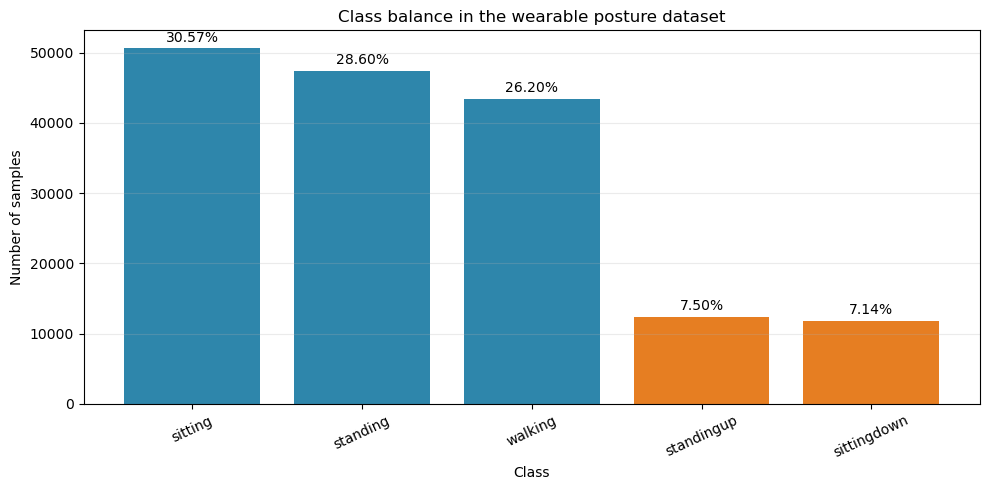

Rows per user:


,row_count
user,
debora,51577
jose_carlos,13161
katia,49797
wallace,51098


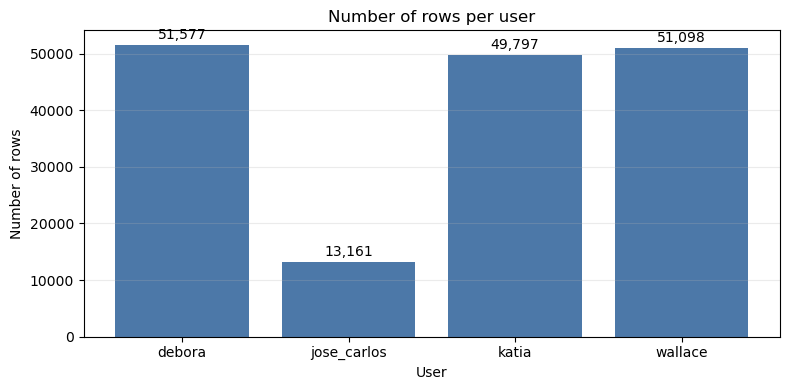

In [40]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_csv('../DATASET/augmented.csv')

class_col = 'class'
transition_classes = ['standingup', 'sittingdown']

class_counts = df[class_col].value_counts().sort_values(ascending=False)
class_summary = class_counts.to_frame(name='count')
class_summary['percentage'] = (class_summary['count'] / len(df) * 100).round(2)
class_summary['share_vs_majority'] = (class_summary['count'] / class_summary['count'].max()).round(4)
class_summary = class_summary.sort_values('count', ascending=False)

print(f'Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns')
print('Class distribution summary:')
display(class_summary)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(class_summary.index.astype(str), class_summary['count'], color=['#2E86AB' if cls not in transition_classes else '#E67E22' for cls in class_summary.index.astype(str)])
ax.set_title('Class balance in the wearable posture dataset')
ax.set_xlabel('Class')
ax.set_ylabel('Number of samples')
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=0.25)

for bar, percentage in zip(bars, class_summary['percentage']):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height + max(class_summary['count']) * 0.01, f'{percentage:.2f}%', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

user_counts = df['user'].value_counts().sort_index()
user_summary = user_counts.to_frame(name='row_count')

print('Rows per user:')
display(user_summary)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(user_summary.index.astype(str), user_summary['row_count'], color='#4C78A8')
ax.set_title('Number of rows per user')
ax.set_xlabel('User')
ax.set_ylabel('Number of rows')
ax.grid(axis='y', alpha=0.25)

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height + max(user_summary['row_count']) * 0.01, f'{int(height):,}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

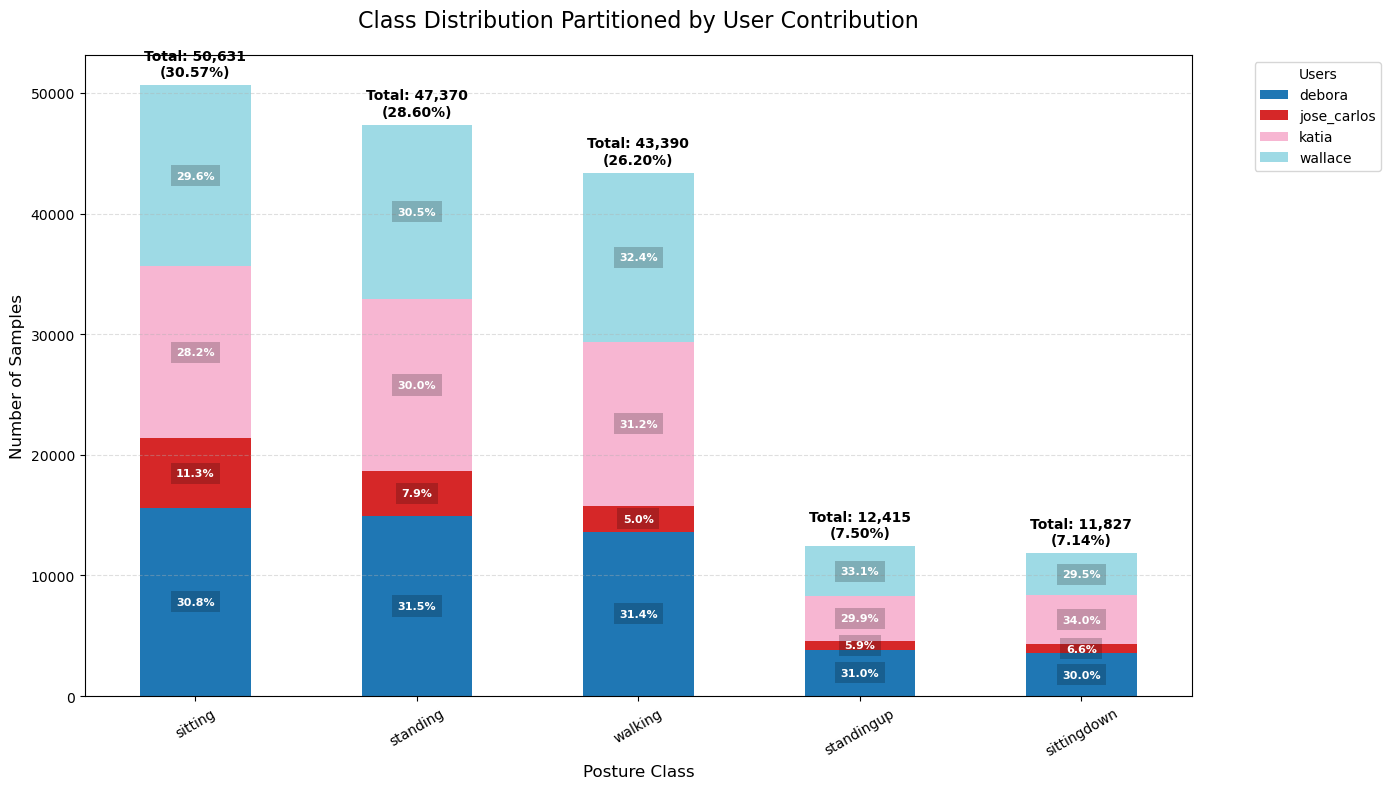

In [49]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Prepare the data: Group by class and user
# We count how many rows each user has for each class
pivot_df = df.groupby(['class', 'user']).size().unstack(fill_value=0)

# 2. Sort classes by total volume (descending) to match your previous logic
pivot_df['total'] = pivot_df.sum(axis=1)
pivot_df = pivot_df.sort_values('total', ascending=False)
total_samples = len(df)

# 3. Create the plot
fig, ax = plt.subplots(figsize=(14, 8))

# Plot the stacked bars
# We drop 'total' column so it's not plotted as a user
plot_df = pivot_df.drop(columns='total')
plot_df.plot(kind='bar', stacked=True, ax=ax, colormap='tab20')

# 4. Add labels
# We need to iterate through each class (bar) and each user (segment)
for i, (idx, row) in enumerate(pivot_df.iterrows()):
    class_total = row['total']
    class_percentage = (class_total / total_samples) * 100
    
    # Cumulative height for placing labels inside the stack
    cumulative_height = 0
    
    # Iterate through users for this specific class
    for user_col in plot_df.columns:
        user_val = row[user_col]
        if user_val > 0:
            user_percentage_in_class = (user_val / class_total) * 100
            
            # Label inside the segment (User %)
            # We only show it if the segment is large enough to fit text
            if user_percentage_in_class > 5:
                ax.text(i, cumulative_height + user_val/2, 
                        f'{user_percentage_in_class:.1f}%', 
                        ha='center', va='center', fontsize=8, color='white', fontweight='bold',
                        bbox=dict(facecolor='black', alpha=0.2, lw=0))
            
            cumulative_height += user_val
            
    # Top label (Overall Class % and Total Count)
    ax.text(i, class_total + (max(pivot_df['total']) * 0.01), 
            f'Total: {int(class_total):,}\n({class_percentage:.2f}%)', 
            ha='center', va='bottom', fontsize=10, fontweight='bold')

# Styling
ax.set_title('Class Distribution Partitioned by User Contribution', fontsize=16, pad=20)
ax.set_xlabel('Posture Class', fontsize=12)
ax.set_ylabel('Number of Samples', fontsize=12)
ax.legend(title='Users', bbox_to_anchor=(1.05, 1), loc='upper left')
ax.tick_params(axis='x', rotation=30)
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [41]:


user_cols = ['user', 'gender', 'age', 'how_tall_in_meters', 'weight', 'body_mass_index']
print('Total rows:', len(df))
print('Unique users:', df['user'].nunique())

# Per-user aggregates (mean) to inspect between-subject variability
per_user = df.groupby('user')[['age', 'how_tall_in_meters', 'weight', 'body_mass_index']].mean()
display(per_user.head())

Total rows: 165633
Unique users: 4


,age,how_tall_in_meters,weight,body_mass_index
user,,,,
debora,46.0,1.62,75.0,28.6
jose_carlos,75.0,1.67,67.0,24.0
katia,28.0,1.58,55.0,22.0
wallace,31.0,1.71,83.0,28.4


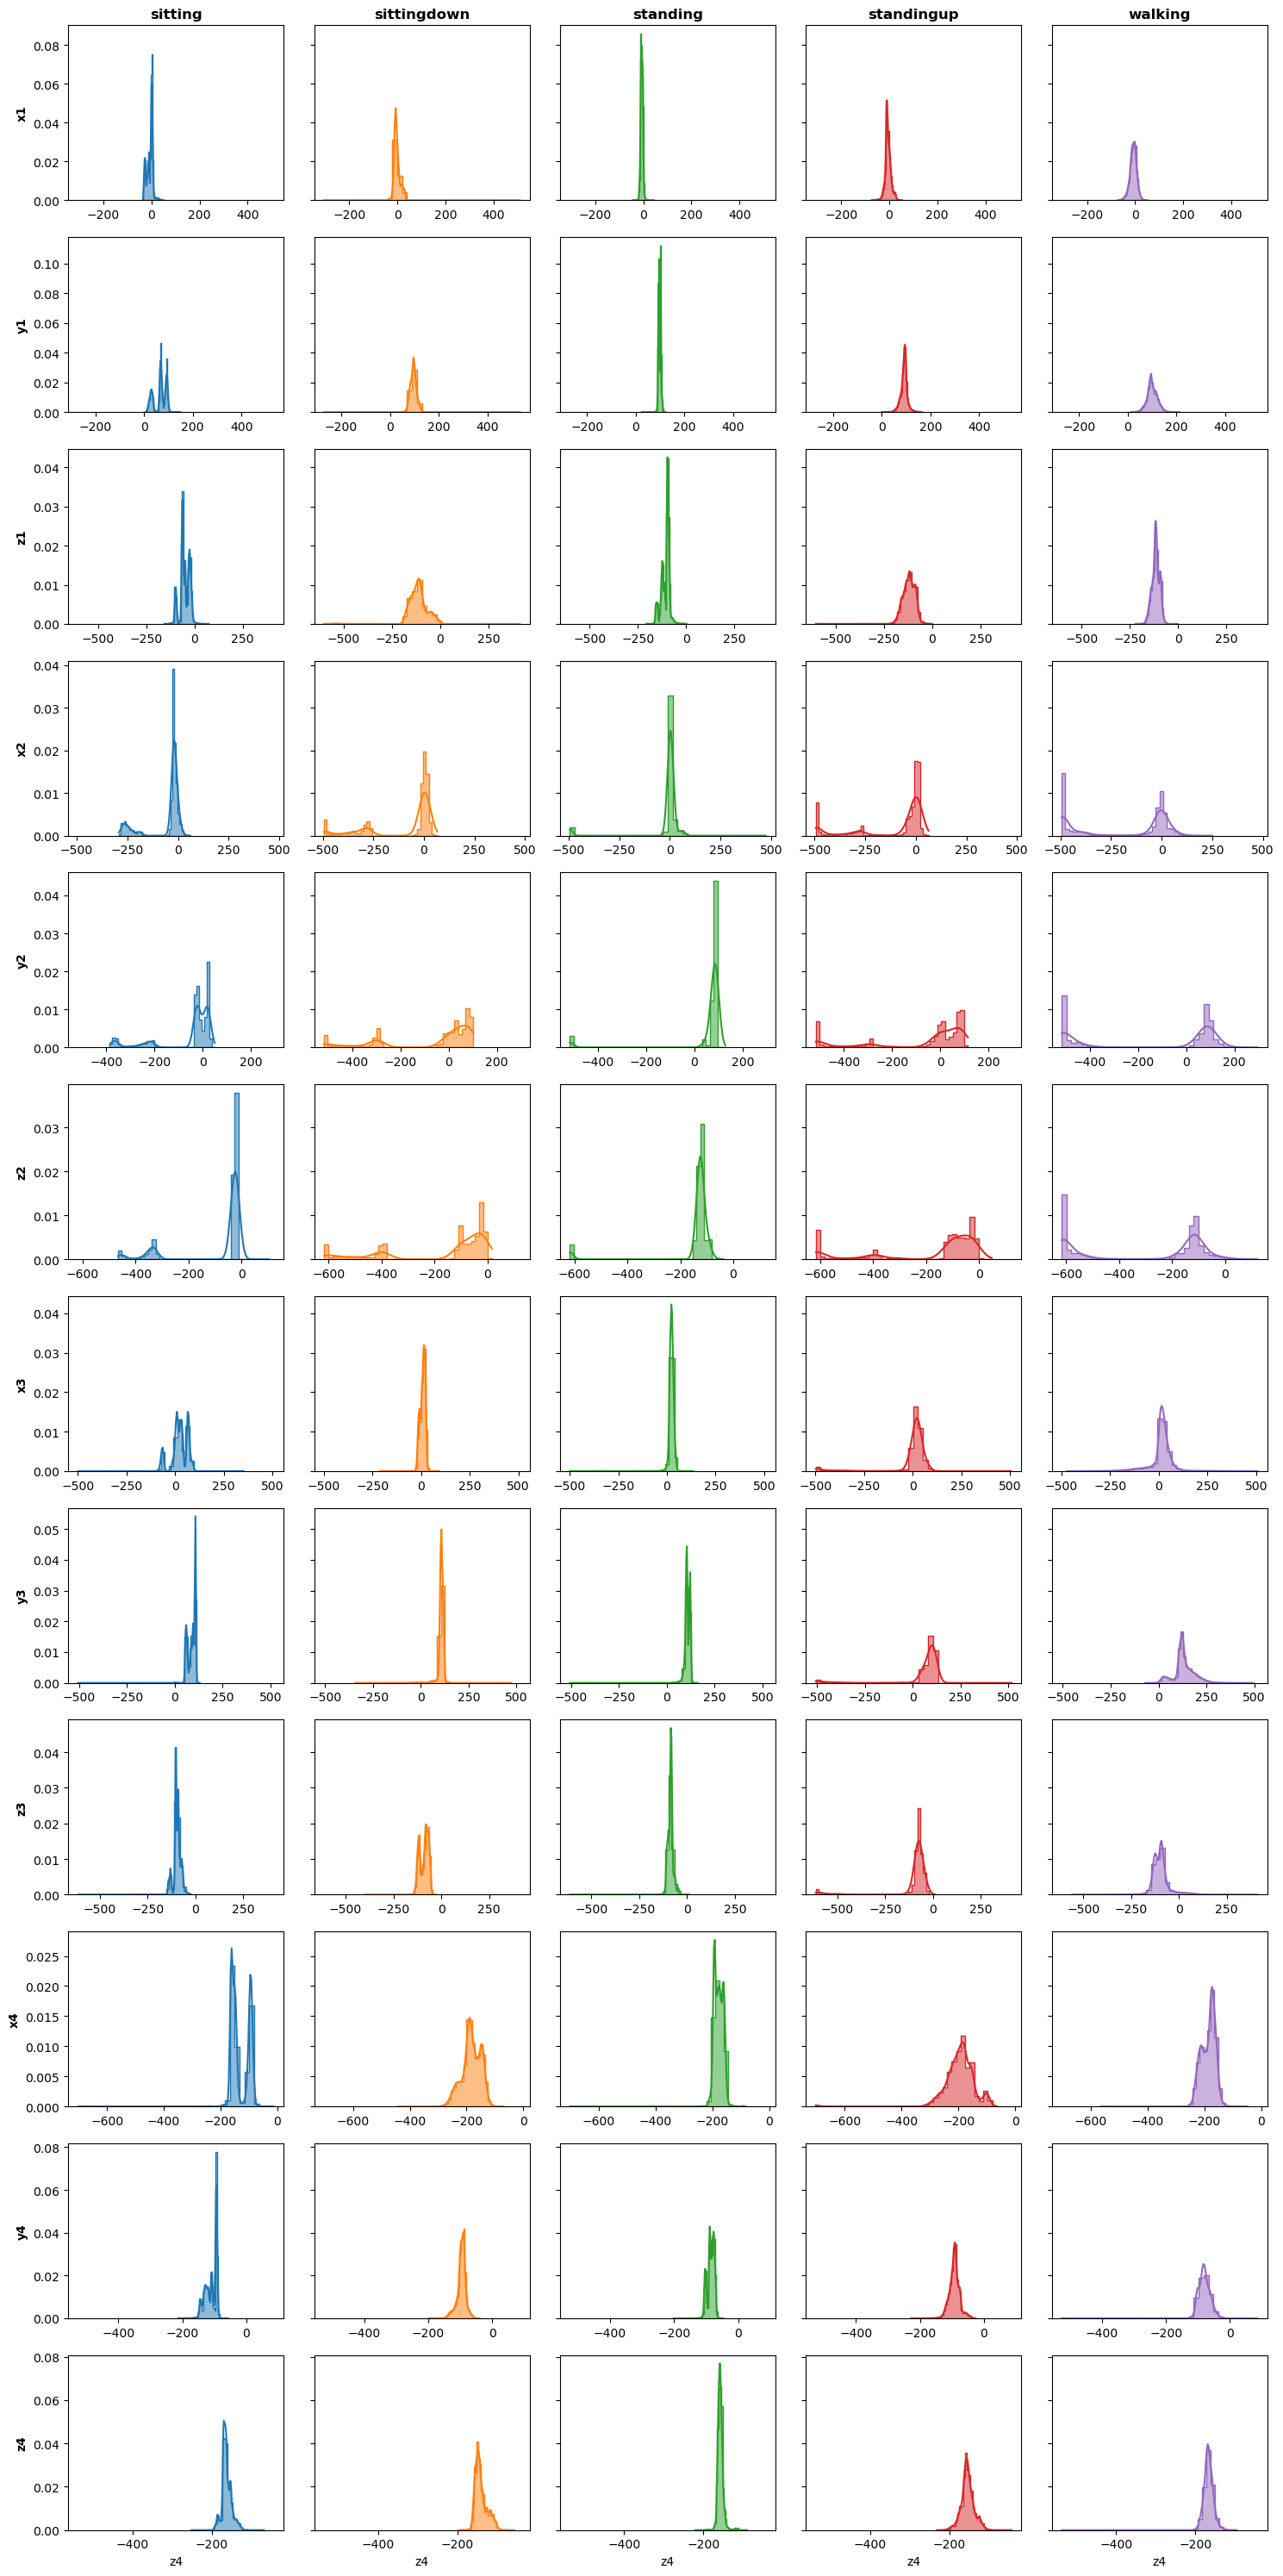

In [42]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

if 'class' in df.columns:
    classes = sorted(df['class'].unique())
    # Seleziona solo le colonne numeriche dei sensori (x1, y1, z1...)
    # present_cols dovrebbe contenere x1, y1, z1, x2, y2, z2, ecc.
    num_sensors = len(present_cols)
    num_classes = len(classes)

    # AGGIUNTA: sharey='row' uniforma l'asse Y per ogni riga
    # AGGIUNTA: sharex='row' uniforma l'asse X per ogni riga (per vedere i range di accelerazione)
    fig, axes = plt.subplots(num_sensors, num_classes, 
                             figsize=(num_classes * 3, num_sensors * 2.5), 
                             sharex='row', 
                             sharey='row') 

    if num_sensors == 1:
        axes = np.atleast_2d(axes)

    for i, sensor in enumerate(present_cols):
        # Calcoliamo i limiti globali per il sensore i-esimo per sicurezza (opzionale con sharex='row')
        sensor_min = df[sensor].min()
        sensor_max = df[sensor].max()
        
        for j, cls in enumerate(classes):
            data_subset = df[df['class'] == cls][sensor].dropna()
            
            # NOTA: stat='density' è fondamentale se le classi sono sbilanciate
            # Se vuoi i conteggi puri, cambia in stat='count'
            sns.histplot(data_subset, bins=40, kde=True, ax=axes[i, j], 
                         color=f'C{j}', stat='density', element="step")
            
            # Etichette delle colonne (Attività)
            if i == 0:
                axes[i, j].set_title(f"{cls}", fontsize=12, fontweight='bold')
            
            # Etichette delle righe (Sensore)
            if j == 0:
                axes[i, j].set_ylabel(sensor, fontsize=10, fontweight='bold')
            else:
                axes[i, j].set_ylabel("") 

            # Pulizia asse X per i grafici intermedi
            if i < num_sensors - 1:
                axes[i, j].set_xlabel("")

    plt.tight_layout()
    plt.show()

C:\Users\matte\AppData\Local\Temp\ipykernel_19352\82113633.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='class', y=sensor, data=df, ax=axes[i], palette='Set2')
C:\Users\matte\AppData\Local\Temp\ipykernel_19352\82113633.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='class', y=sensor, data=df, ax=axes[i], palette='Set2')
C:\Users\matte\AppData\Local\Temp\ipykernel_19352\82113633.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='class', y=sensor, data=df, ax=axes[i], palette='Set2')
C:\Users\matte\AppData\Local\Temp\ipy

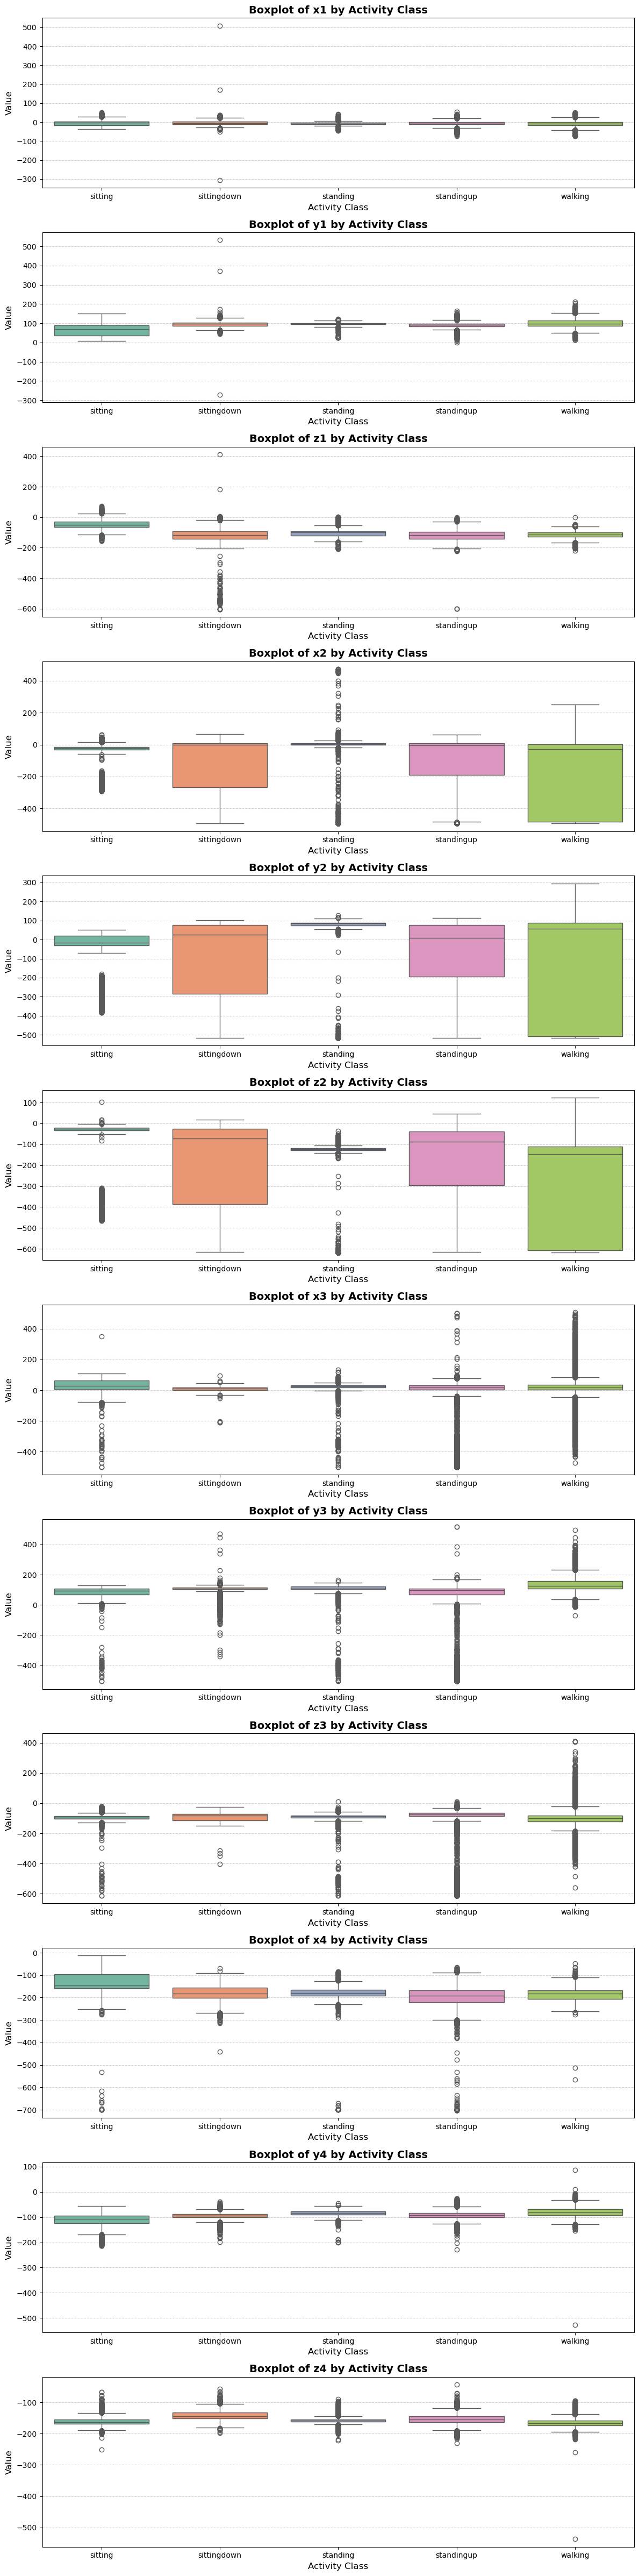

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

if 'class' in df.columns:
    num_sensors = len(present_cols)
    
    # We create one row per sensor. 
    # All activity classes are shown on the X-axis for easy comparison.
    fig, axes = plt.subplots(num_sensors, 1, figsize=(12, num_sensors * 4))

    # Ensure axes is an array even if there is only one sensor
    if num_sensors == 1:
        axes = [axes]

    for i, sensor in enumerate(present_cols):
        # Create the boxplot
        sns.boxplot(x='class', y=sensor, data=df, ax=axes[i], palette='Set2')
        
        # Formatting and labeling
        axes[i].set_title(f'Boxplot of {sensor} by Activity Class', fontsize=14, fontweight='bold')
        axes[i].set_xlabel('Activity Class', fontsize=12)
        axes[i].set_ylabel('Value', fontsize=12)
        
        # Add a light grid for better readability of values
        axes[i].grid(axis='y', linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

C:\Users\matte\AppData\Local\Temp\ipykernel_19352\3040250098.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='class', y=sensor, data=df, ax=axes[i], palette='Set2')


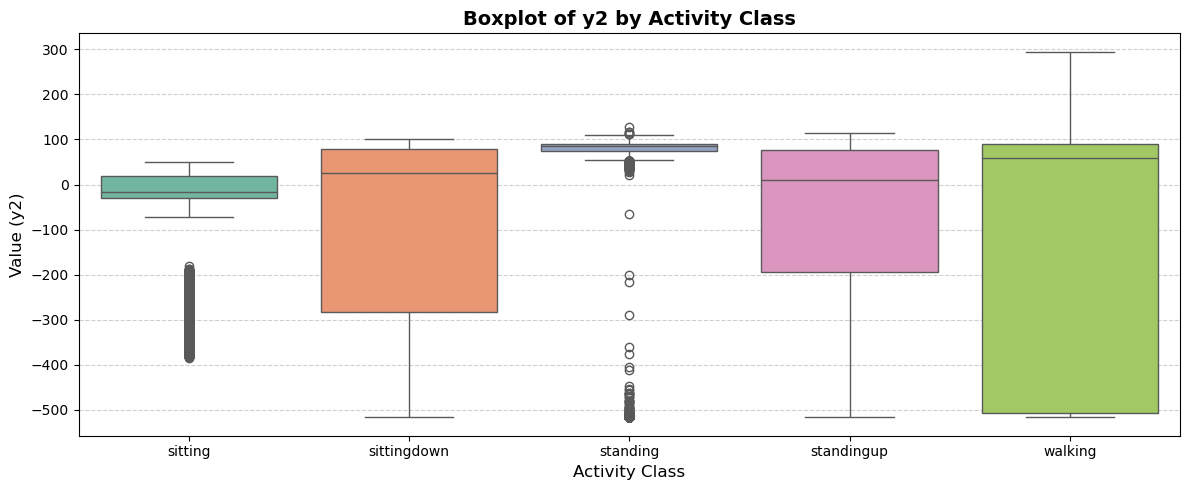

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

# Lista dei sensori da visualizzare
sensors_to_plot = ['y2']

# Filtriamo solo quelli effettivamente presenti nel dataframe
available_sensors = [s for s in sensors_to_plot if s in df.columns]

if available_sensors and 'class' in df.columns:
    # Creiamo una figura con 3 righe (una per sensore)
    fig, axes = plt.subplots(len(available_sensors), 1, figsize=(12, 5 * len(available_sensors)))

    # Se c'è solo un sensore, axes non è una lista, quindi lo trasformiamo in lista
    if len(available_sensors) == 1:
        axes = [axes]

    for i, sensor in enumerate(available_sensors):
        # Creazione del boxplot per il sensore corrente
        sns.boxplot(x='class', y=sensor, data=df, ax=axes[i], palette='Set2')
        
        # Formattazione e labeling
        axes[i].set_title(f'Boxplot of {sensor} by Activity Class', fontsize=14, fontweight='bold')
        axes[i].set_xlabel('Activity Class', fontsize=12)
        axes[i].set_ylabel(f'Value ({sensor})', fontsize=12)
        
        # Aggiunta di una griglia leggera
        axes[i].grid(axis='y', linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()
else:
    print("Errore: le colonne del sensore 2 o la colonna 'class' non sono presenti nel DataFrame.")

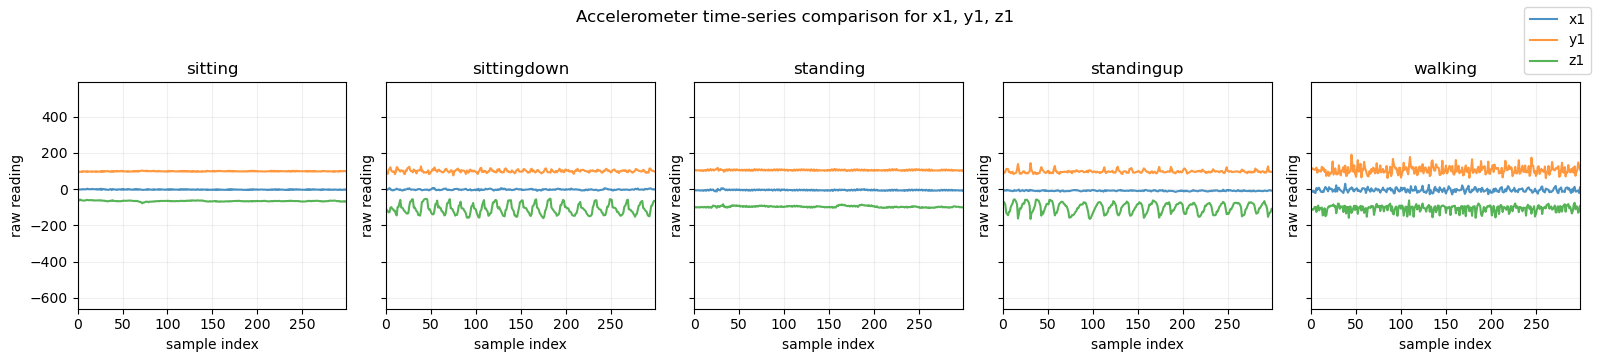

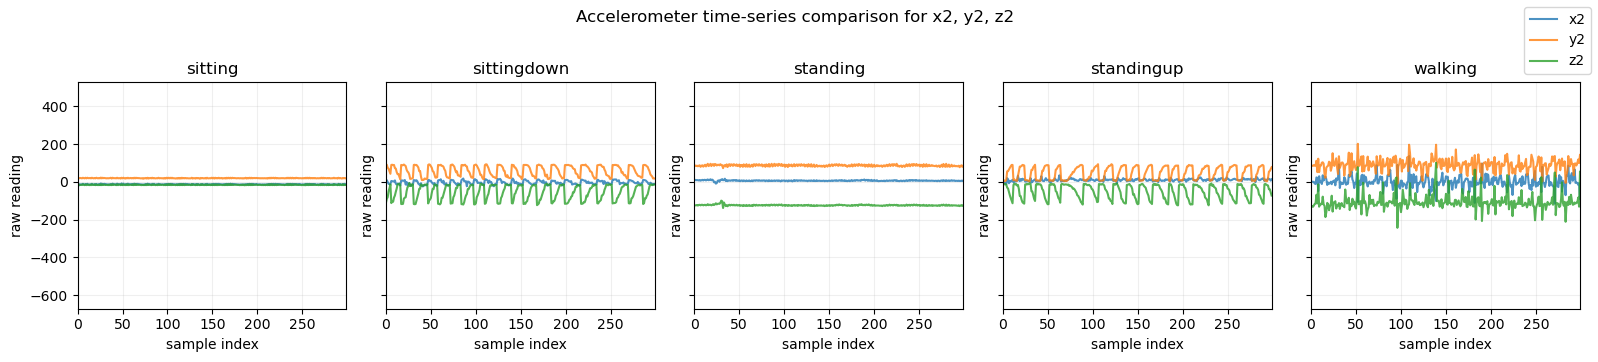

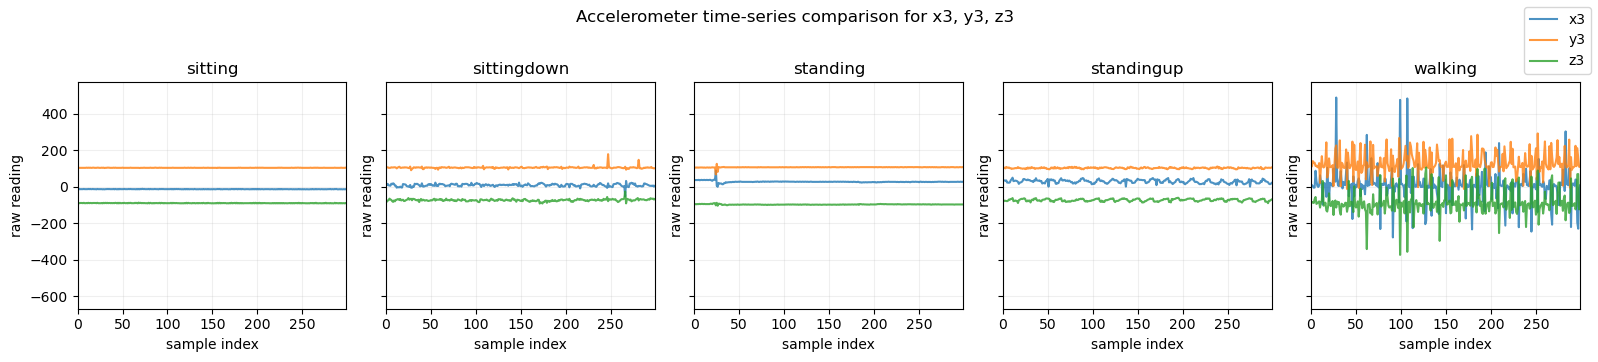

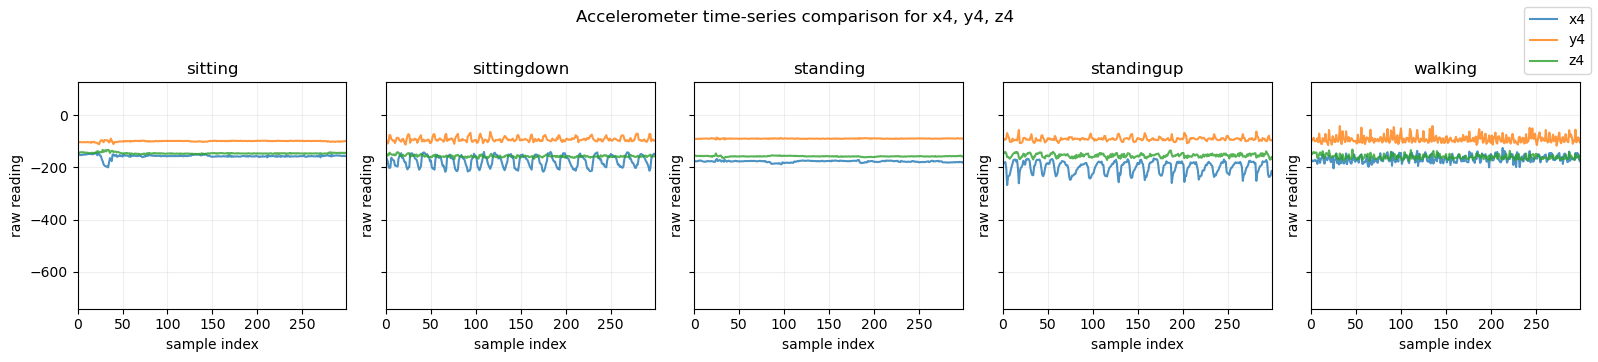

In [45]:
# Sensor-wise class comparison: one figure per accelerometer triple, with all classes as subplots
class_col = 'class' if 'class' in df.columns else None
if class_col is not None:
    class_values = list(df[class_col].dropna().cat.categories if hasattr(df[class_col].dtype, 'categories') else df[class_col].dropna().unique())
    sensor_groups = [
        ('x1, y1, z1', ['x1', 'y1', 'z1']),
        ('x2, y2, z2', ['x2', 'y2', 'z2']),
        ('x3, y3, z3', ['x3', 'y3', 'z3']),
        ('x4, y4, z4', ['x4', 'y4', 'z4']),
    ]
    for sensor_name, sensor_axes in sensor_groups:
        available_axes = [axis for axis in sensor_axes if axis in present_cols]
        if len(available_axes) == 0:
            continue
        sensor_values = df[available_axes].to_numpy().ravel()
        sensor_values = sensor_values[~np.isnan(sensor_values)]
        if len(sensor_values) > 0:
            lower = float(np.min(sensor_values))
            upper = float(np.max(sensor_values))
            padding = 0.05 * (upper - lower if upper > lower else 1.0)
            y_limits = (lower - padding, upper + padding)
        else:
            y_limits = None

        n_classes = len(class_values)
        n_cols = 5
        n_rows = int(np.ceil(n_classes / n_cols))
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.5 * n_rows), sharex=True, sharey=True)
        axes = np.array(axes).ravel()

        for ax, class_name in zip(axes, class_values):
            class_sample = df[df[class_col] == class_name].head(300)
            if len(class_sample) == 0:
                ax.axis('off')
                continue
            for axis in available_axes:
                ax.plot(class_sample[axis].values, label=axis, alpha=0.8)
            ax.set_title(f'{class_name}')
            ax.set_xlabel('sample index')
            ax.set_ylabel('raw reading')
            ax.set_xlim(0, max(len(class_sample) - 1, 1))
            if y_limits is not None:
                ax.set_ylim(*y_limits)
            ax.grid(True, alpha=0.2)

        for ax in axes[len(class_values):]:
            ax.axis('off')

        handles, labels = axes[0].get_legend_handles_labels() if len(class_values) > 0 else ([], [])
        if handles:
            fig.legend(handles, labels, loc='upper right')
        fig.suptitle(f'Accelerometer time-series comparison for {sensor_name}', y=1.02)
        plt.tight_layout()
        plt.show()

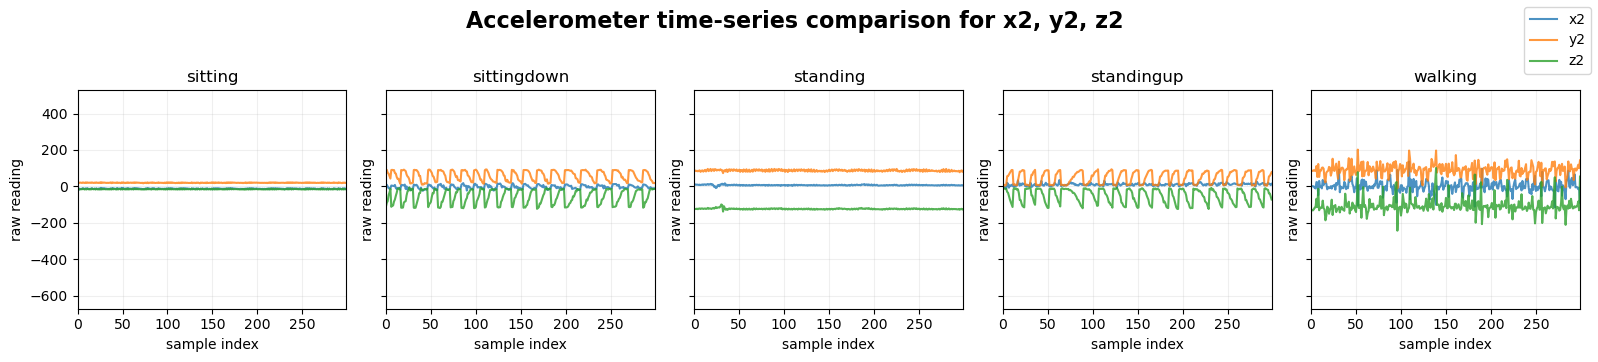

In [46]:
import matplotlib.pyplot as plt
import numpy as np

# Verifichiamo la colonna class
class_col = 'class' if 'class' in df.columns else None

if class_col is not None:
    # Definiamo le classi
    class_values = list(df[class_col].dropna().cat.categories if hasattr(df[class_col].dtype, 'categories') else df[class_col].dropna().unique())
    
    # Filtriamo per considerare SOLO il sensore 2
    sensor_name = 'x2, y2, z2'
    sensor_axes = ['x2', 'y2', 'z2']
    
    # Verifichiamo quali assi del sensore 2 sono effettivamente presenti nel dataframe
    available_axes = [axis for axis in sensor_axes if axis in present_cols]
    
    if len(available_axes) > 0:
        # Calcolo dei limiti dell'asse Y per coerenza tra tutti i subplot
        sensor_values = df[available_axes].to_numpy().ravel()
        sensor_values = sensor_values[~np.isnan(sensor_values)]
        if len(sensor_values) > 0:
            lower = float(np.min(sensor_values))
            upper = float(np.max(sensor_values))
            padding = 0.05 * (upper - lower if upper > lower else 1.0)
            y_limits = (lower - padding, upper + padding)
        else:
            y_limits = None

        # Configurazione della griglia di subplot
        n_classes = len(class_values)
        n_cols = 5
        n_rows = int(np.ceil(n_classes / n_cols))
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.5 * n_rows), sharex=True, sharey=True)
        axes = np.array(axes).ravel()

        # Ciclo su ogni classe per creare i subplot
        for ax, class_name in zip(axes, class_values):
            class_sample = df[df[class_col] == class_name].head(300)
            if len(class_sample) == 0:
                ax.axis('off')
                continue
            
            for axis in available_axes:
                ax.plot(class_sample[axis].values, label=axis, alpha=0.8)
            
            ax.set_title(f'{class_name}')
            ax.set_xlabel('sample index')
            ax.set_ylabel('raw reading')
            ax.set_xlim(0, max(len(class_sample) - 1, 1))
            if y_limits is not None:
                ax.set_ylim(*y_limits)
            ax.grid(True, alpha=0.2)

        # Nascondi i subplot vuoti
        for ax in axes[len(class_values):]:
            ax.axis('off')

        # Legenda e titolo globale
        handles, labels = axes[0].get_legend_handles_labels() if len(class_values) > 0 else ([], [])
        if handles:
            fig.legend(handles, labels, loc='upper right')
        
        fig.suptitle(f'Accelerometer time-series comparison for {sensor_name}', y=1.02, fontsize=16, fontweight='bold')
        plt.tight_layout()
        plt.show()
    else:
        print("Il sensore 2 (x2, y2, z2) non è presente nei dati.")

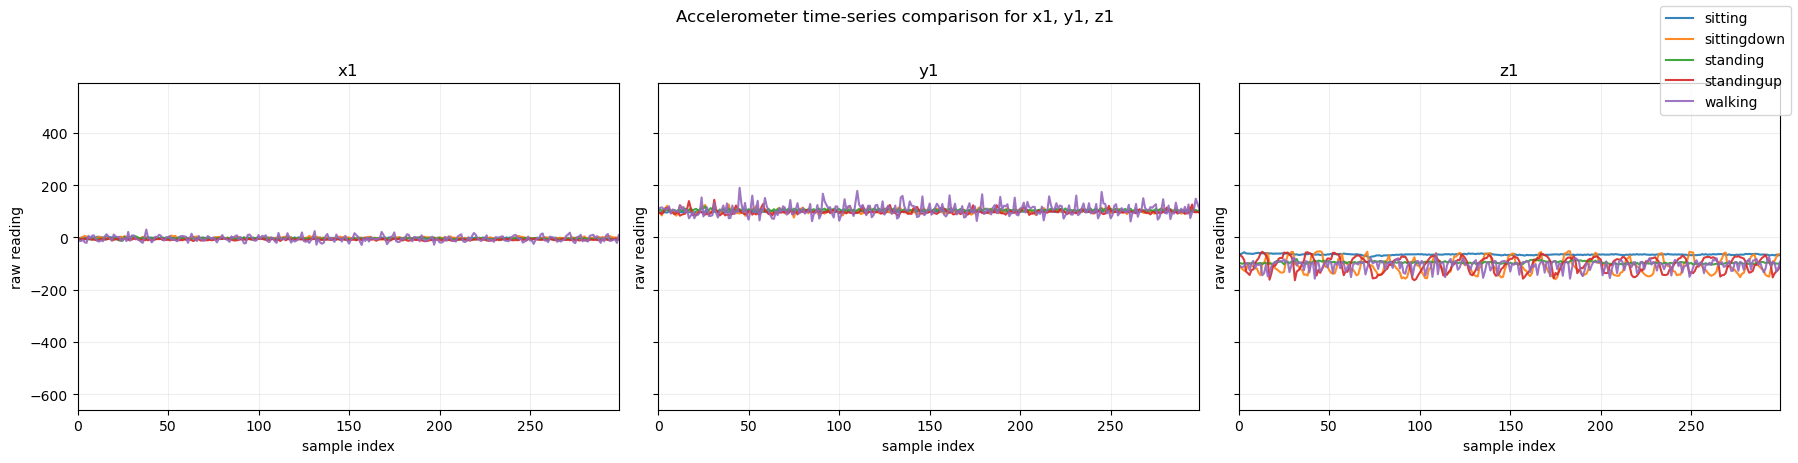

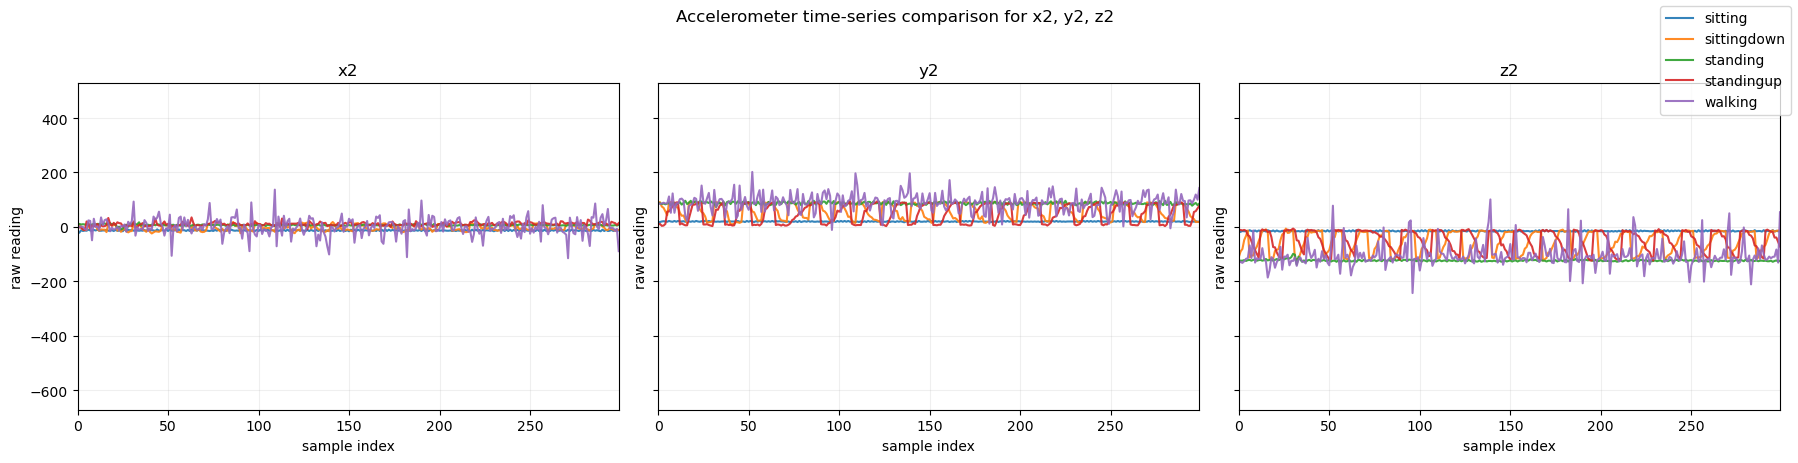

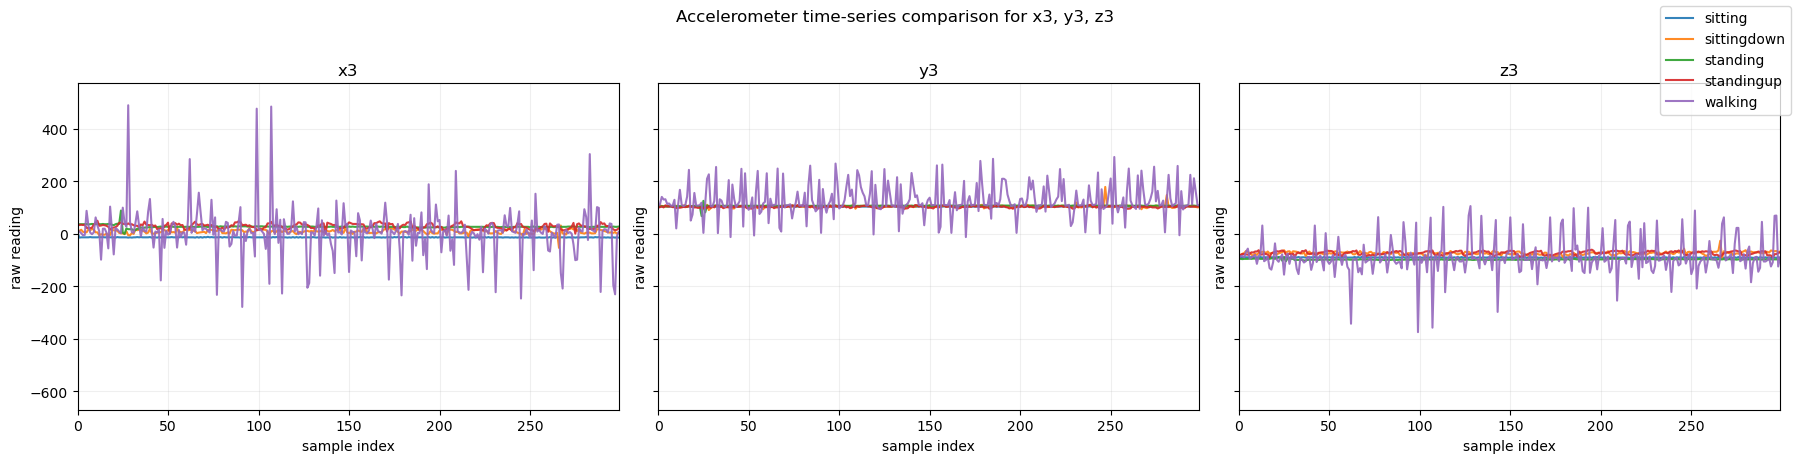

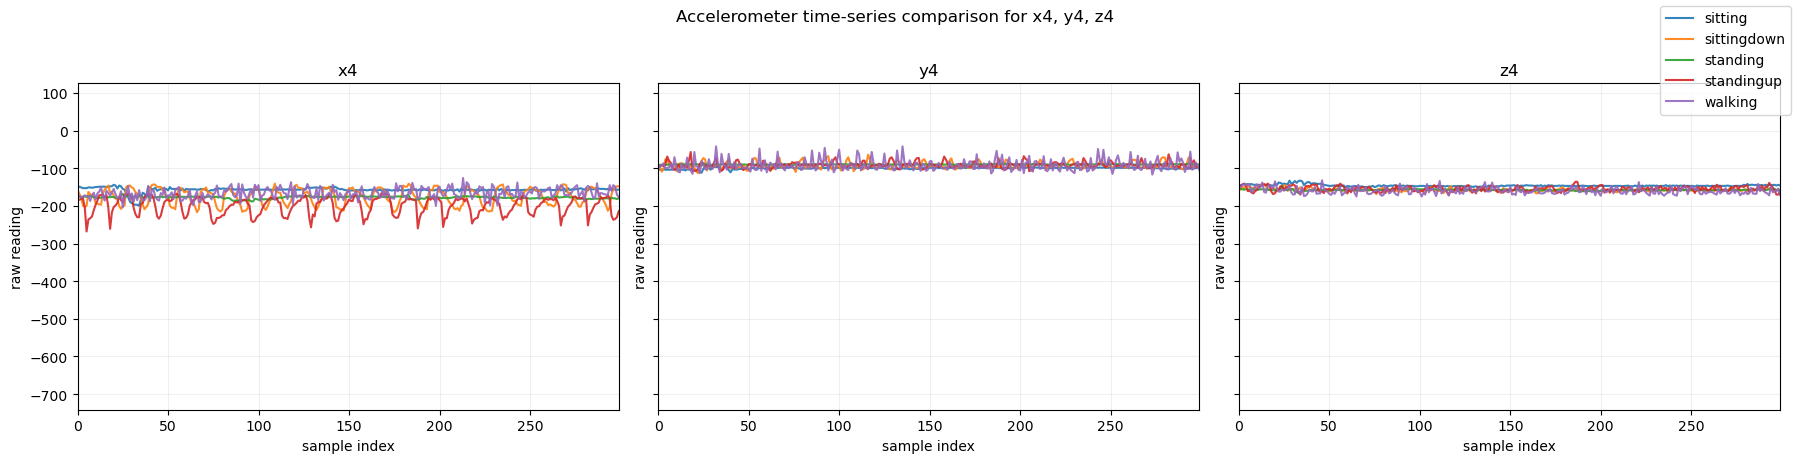

In [47]:
# Sensor-wise class comparison: one figure per accelerometer triple, with all classes overlaid in the same graph
class_col = 'class' if 'class' in df.columns else None
if class_col is not None:
    class_values = list(df[class_col].dropna().cat.categories if hasattr(df[class_col].dtype, 'categories') else df[class_col].dropna().unique())
    sensor_groups = [
        ('x1, y1, z1', ['x1', 'y1', 'z1']),
        ('x2, y2, z2', ['x2', 'y2', 'z2']),
        ('x3, y3, z3', ['x3', 'y3', 'z3']),
        ('x4, y4, z4', ['x4', 'y4', 'z4']),
    ]
    for sensor_name, sensor_axes in sensor_groups:
        available_axes = [axis for axis in sensor_axes if axis in present_cols]
        if len(available_axes) == 0:
            continue
        sensor_values = df[available_axes].to_numpy().ravel()
        sensor_values = sensor_values[~np.isnan(sensor_values)]
        if len(sensor_values) > 0:
            lower = float(np.min(sensor_values))
            upper = float(np.max(sensor_values))
            padding = 0.05 * (upper - lower if upper > lower else 1.0)
            y_limits = (lower - padding, upper + padding)
        else:
            y_limits = None

        fig, axes = plt.subplots(1, len(available_axes), figsize=(18, 4.5), sharex=True, sharey=True)
        axes = np.array([axes]).ravel() if len(available_axes) == 1 else np.array(axes).ravel()
        palette = sns.color_palette('tab10', n_colors=len(class_values))

        for ax, axis in zip(axes, available_axes):
            for class_idx, class_name in enumerate(class_values):
                class_sample = df[df[class_col] == class_name].head(300)
                if len(class_sample) == 0 or axis not in class_sample.columns:
                    continue
                ax.plot(class_sample[axis].values, label=class_name, color=palette[class_idx], alpha=0.9)
            ax.set_title(axis)
            ax.set_xlabel('sample index')
            ax.set_ylabel('raw reading')
            ax.set_xlim(0, max(len(df[df[class_col] == class_values[0]].head(300)) - 1, 1))
            if y_limits is not None:
                ax.set_ylim(*y_limits)
            ax.grid(True, alpha=0.2)

        handles, labels = axes[0].get_legend_handles_labels() if len(available_axes) > 0 else ([], [])
        if handles:
            fig.legend(handles, labels, loc='upper right')
        fig.suptitle(f'Accelerometer time-series comparison for {sensor_name}', y=1.02)
        plt.tight_layout()
        plt.show()
else:
    print('No class label present; skipping class-wise comparison plots.')

Mean Absolute Value (MAV) per axis:


class,sitting,sittingdown,standing,standingup,walking
x1,10.480674,9.991968,6.835655,10.378574,12.488154
y1,65.987103,96.563541,97.748406,91.332501,100.889652
z1,49.763129,115.528621,106.779776,120.068304,115.453008
x2,60.320594,104.534117,32.640405,111.595087,205.667458
y2,69.957674,137.741016,103.454697,141.963190,253.808619


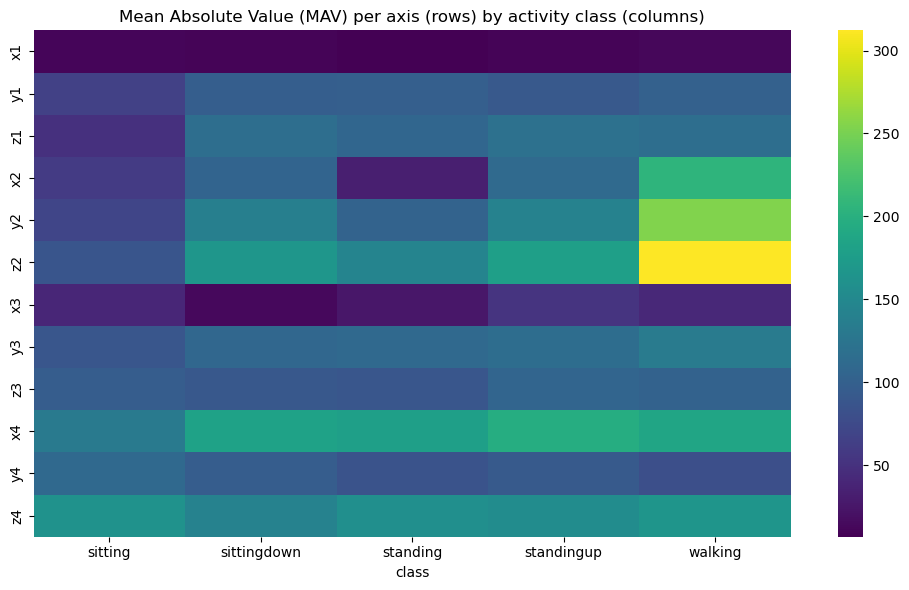

Variance per axis:


class,sitting,sittingdown,standing,standingup,walking
x1,162.618519,181.673404,22.826385,142.441829,201.664984
y1,639.896199,191.945462,25.580981,189.729131,440.579632
z1,627.193907,2852.235908,442.807846,958.374261,398.665507
x2,8195.579007,27722.369821,11752.890710,31964.556740,53485.643068
y2,13514.459246,37539.235449,16475.132592,43412.661474,81466.826975


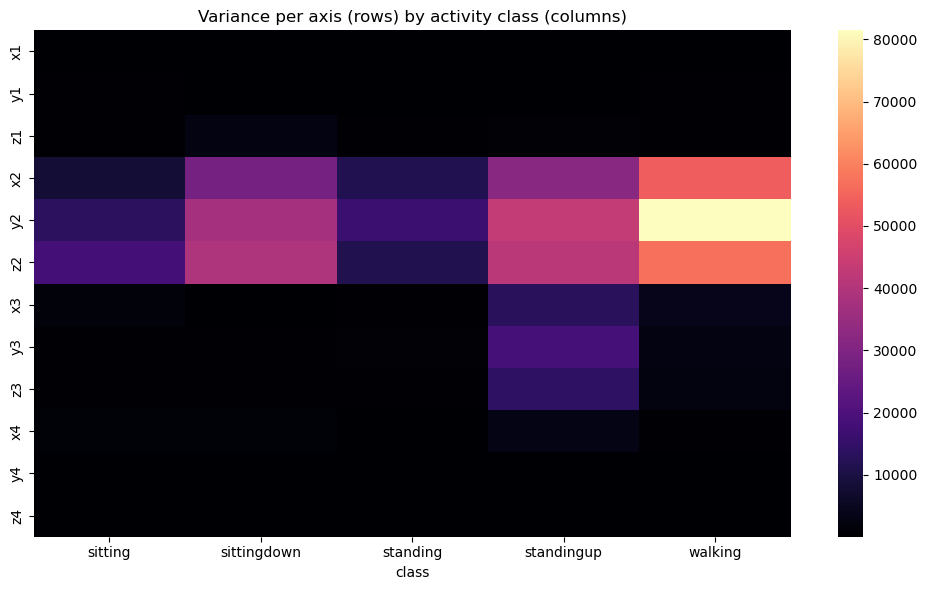

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

# Check if 'class' column exists before proceeding
if 'class' in df.columns:
    
    # 1. Mean Absolute Value (MAV) per axis grouped by activity class
    # Helps identify which sensors have the strongest average signal per activity
    mav = df.groupby('class', observed=False)[present_cols].apply(lambda x: x.abs().mean()).T
    
    print("Mean Absolute Value (MAV) per axis:")
    display(mav.head())
    
    plt.figure(figsize=(10, 6))
    sns.heatmap(mav, cmap='viridis')
    plt.title('Mean Absolute Value (MAV) per axis (rows) by activity class (columns)')
    plt.tight_layout()
    plt.show()

    # 2. Variance per axis grouped by activity class
    # Helps identify which sensors have the most fluctuations/turbulence per activity
    vav = df.groupby('class', observed=False)[present_cols].var().T
    
    print("Variance per axis:")
    display(vav.head())
    
    plt.figure(figsize=(10, 6))
    sns.heatmap(vav, cmap='magma')
    plt.title('Variance per axis (rows) by activity class (columns)')
    plt.tight_layout()
    plt.show()